In [41]:
import warnings
from urllib3.exceptions import NotOpenSSLWarning

warnings.filterwarnings("ignore", category=NotOpenSSLWarning)
warnings.filterwarnings("ignore", message=".*'M' is deprecated.*")
warnings.filterwarnings("ignore", message=".*previous implementation of stack is deprecated.*")

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

BASE_DIR = Path("../").resolve()
if not (BASE_DIR / "data").exists() and (BASE_DIR.parent / "data").exists():
    print("www")
    BASE_DIR = BASE_DIR.parent

DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"
PLOTS_DIR = RESULTS_DIR / "plots"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

stock_prices = pd.read_csv(DATA_DIR / "stock_prices.csv")
sp500 = pd.read_csv(DATA_DIR / "sp500.csv")

stock_prices["Date"] = pd.to_datetime(stock_prices["Date"])
sp500["Date"] = pd.to_datetime(sp500["Date"])

stock_prices = stock_prices.sort_values("Date").reset_index(drop=True)
sp500 = sp500.sort_values("Date").reset_index(drop=True)

stock_prices.head()

,Date,A,AA,AAPL,ABBV,ABC,ABT,ACE,ACI,ACN,...,XOM,XRAY,XRX,XYL,YHOO,YUM,ZION,ZLC,ZMH,ZNGA
0,2000-12-12,38.407538,24.494157,1.040282,NaN,9.300100,40.196083,31.011163,4.238186,NaN,...,31.374321,11.567392,4.709992,NaN,17.905,7.531124,49.197351,13.19,NaN,NaN
1,2000-12-13,39.038160,25.323023,1.014579,NaN,9.513010,41.493506,29.534441,4.238186,NaN,...,31.783898,11.743036,4.872700,NaN,17.440,7.292677,48.738634,12.81,NaN,NaN
2,2000-12-14,39.749286,24.594860,0.976702,NaN,9.766690,38.538265,28.796080,4.238186,NaN,...,30.990116,11.567392,5.403645,NaN,16.000,7.109094,47.640991,12.94,NaN,NaN
3,2000-12-15,38.159315,23.967401,0.950999,NaN,10.419011,37.489114,28.102020,4.100917,NaN,...,30.489925,11.683442,5.352263,NaN,16.500,7.056340,46.690792,12.47,NaN,NaN
4,2000-12-18,38.239820,25.028660,0.963850,NaN,10.899191,39.691530,29.165260,4.289662,NaN,...,31.309079,11.918679,5.463590,NaN,16.000,7.398184,47.821201,12.25,NaN,NaN


## Missing values analysis

In [42]:
missing_per_variable = stock_prices.isna().sum().sort_values(ascending=False)

missing_per_year = (
    stock_prices.assign(year=stock_prices["Date"].dt.year)
    .drop(columns="Date")
    .groupby("year")
    .agg(lambda col: col.isna().sum())
    .sum(axis=1)
    .rename("missing_values")
)

print("Missing values per variable:")
display(missing_per_variable.head(20))

print("\nMissing values per year:")
display(missing_per_year)

Missing values per variable:


GOOG    3456
NWSA    3264
ABBV    3137
ADT     3086
KRFT    3069
FB      2992
PSX     2968
ZNGA    2890
WPX     2886
TRIP    2882
DLPH    2867
GRPN    2856
XYL     2843
MPC     2764
P       2759
KMI     2672
ECYT    2664
GM      2616
MCP     2534
TSLA    2514
dtype: int64


Missing values per year:


year
2000     1170
2001    27628
2002    22023
2003    20443
2004    20397
2005    17205
2006    15147
2007    13959
2008    11032
2009    11260
2010     9924
2011     7717
2012     7221
2013     5264
2014     6327
Name: missing_values, dtype: int64

## Average price per company, Missing values per company

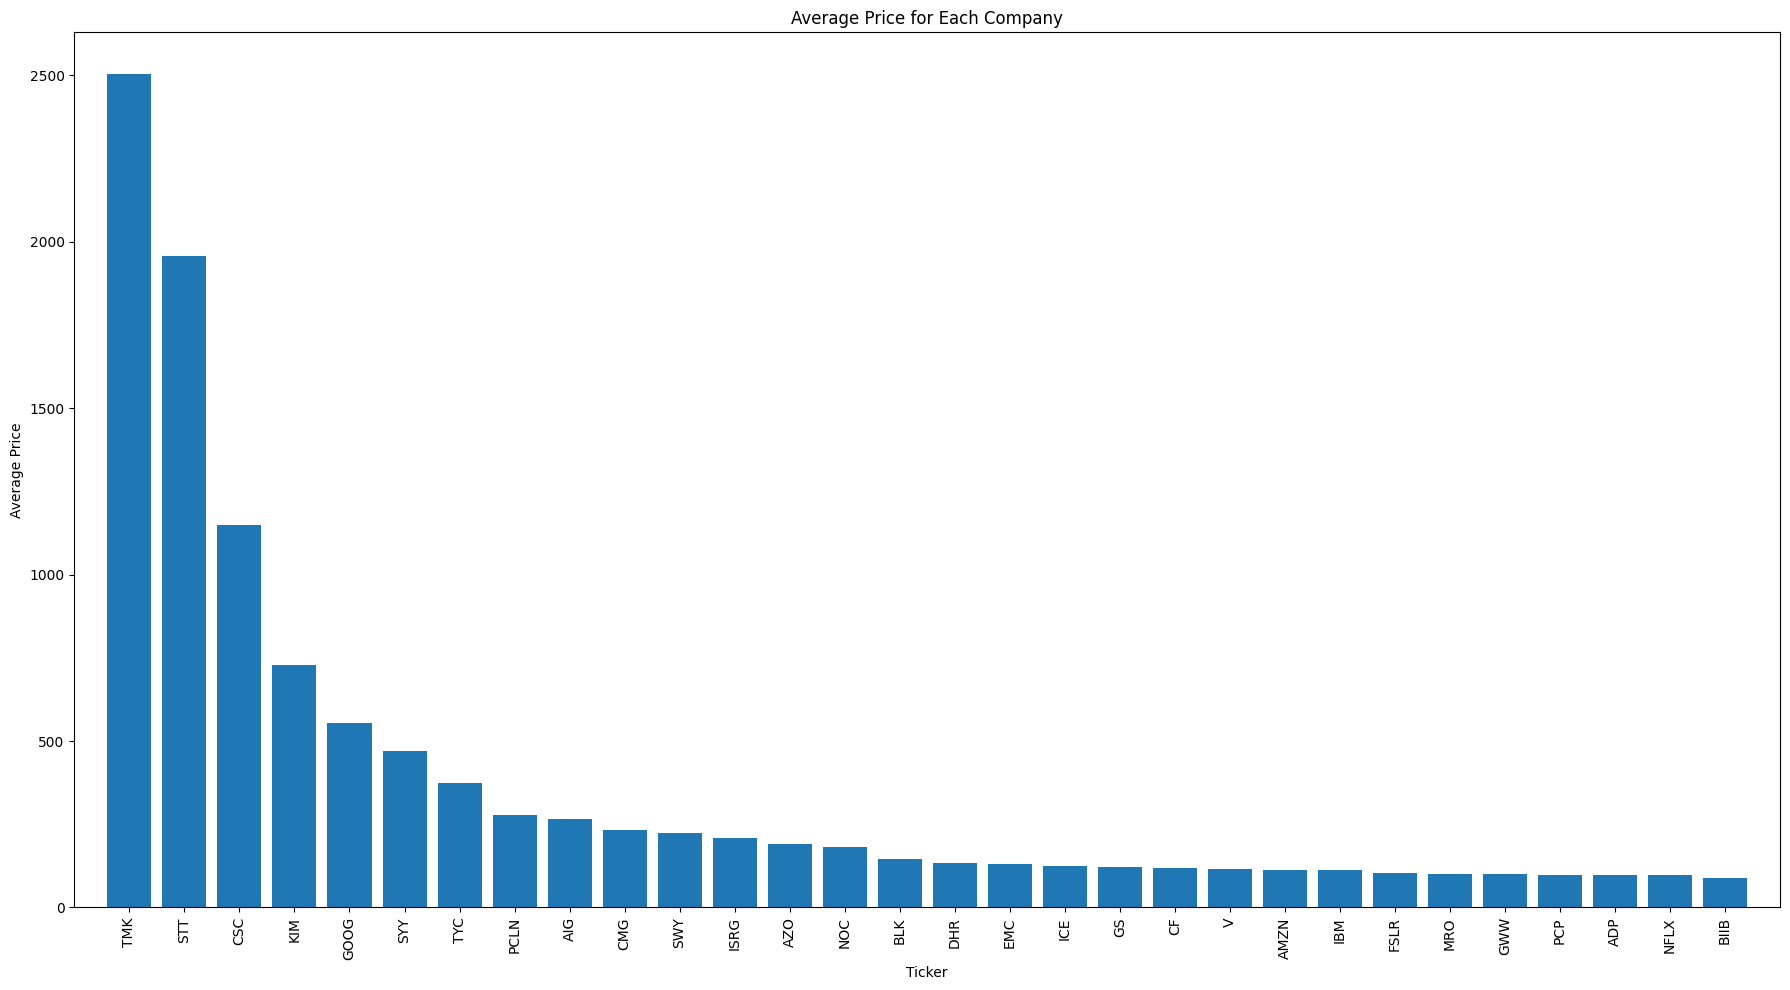

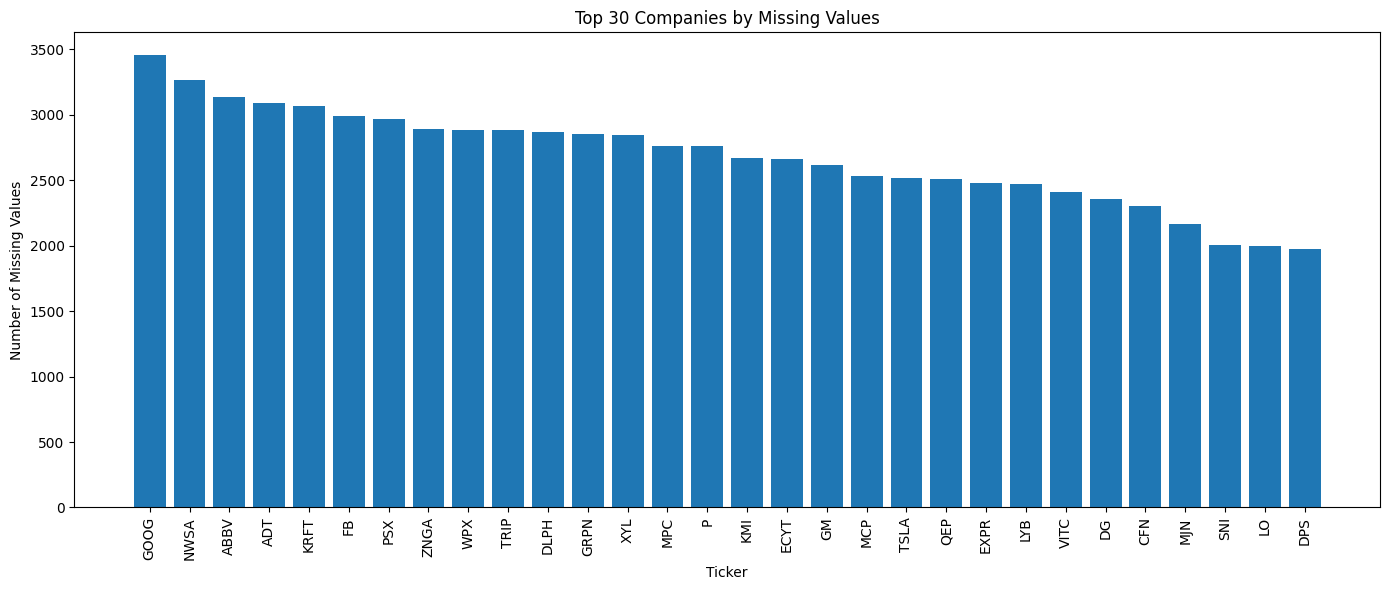

In [43]:
def save_average_price_per_company_plot(prices_df, plot=False):
    # Filter out invalid price ranges (same as preprocessing)
    filtered_df = prices_df.drop(columns="Date").mask((prices_df.drop(columns="Date") < 0.1) | (prices_df.drop(columns="Date") > 10000))
    avg_price = filtered_df.mean(skipna=True).sort_values(ascending=False).head(30)

    fig, ax = plt.subplots(figsize=(18, 10))
    ax.bar(avg_price.index, avg_price.values)
    ax.set_title("Average Price for Each Company")
    ax.set_xlabel("Ticker")
    ax.set_ylabel("Average Price")
    ax.set_xlim(-1, len(avg_price))  # Limit x-axis to top_n companies
    ax.tick_params(axis="x", rotation=90)

    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "average_price_per_company.png", dpi=150)

    if plot:
        plt.show()
    else:
        plt.close(fig)

    return avg_price


def save_missing_values_top_companies_plot(prices_df, plot=False, top_n=30):
    missing_counts = prices_df.drop(columns="Date").isna().sum().sort_values(ascending=False).head(top_n)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.bar(missing_counts.index, missing_counts.values)
    ax.set_title(f"Top {top_n} Companies by Missing Values")
    ax.set_xlabel("Ticker")
    ax.set_ylabel("Number of Missing Values")
    
    ax.tick_params(axis="x", rotation=90)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "missing_values_top_companies.png", dpi=150)

    if plot:
        plt.show()
    else:
        plt.close(fig)

    return missing_counts


avg_price_per_company = save_average_price_per_company_plot(stock_prices, plot=True)
_ = save_missing_values_top_companies_plot(stock_prices, plot=True)

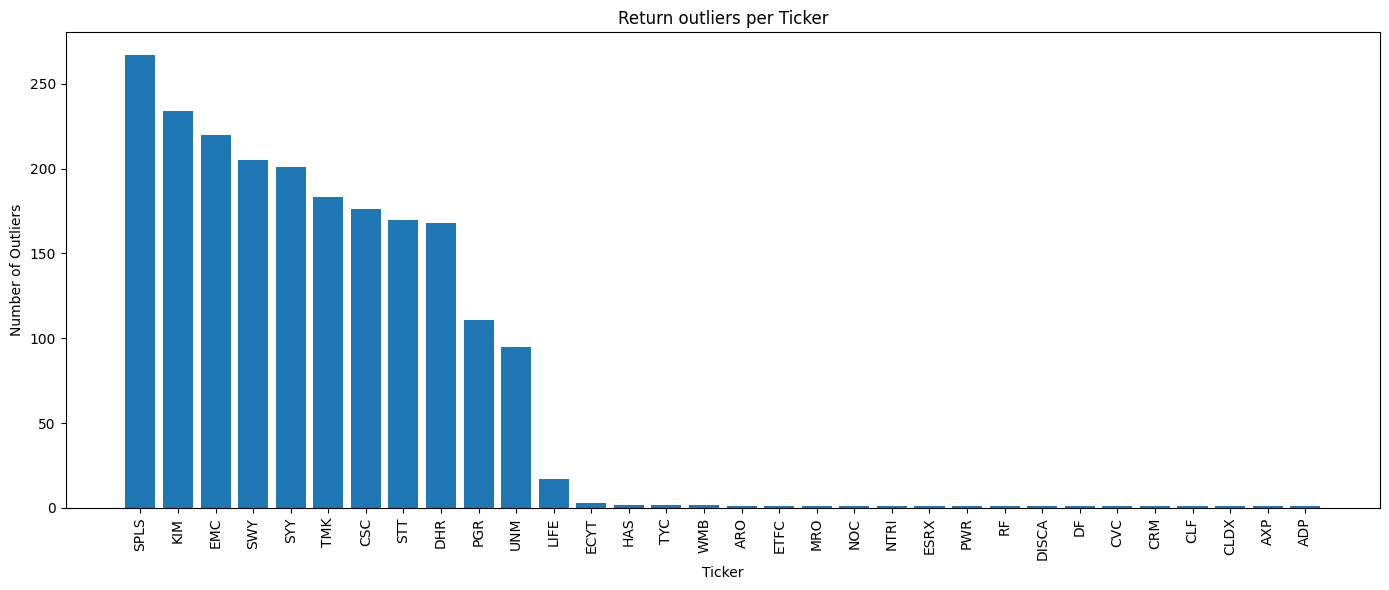

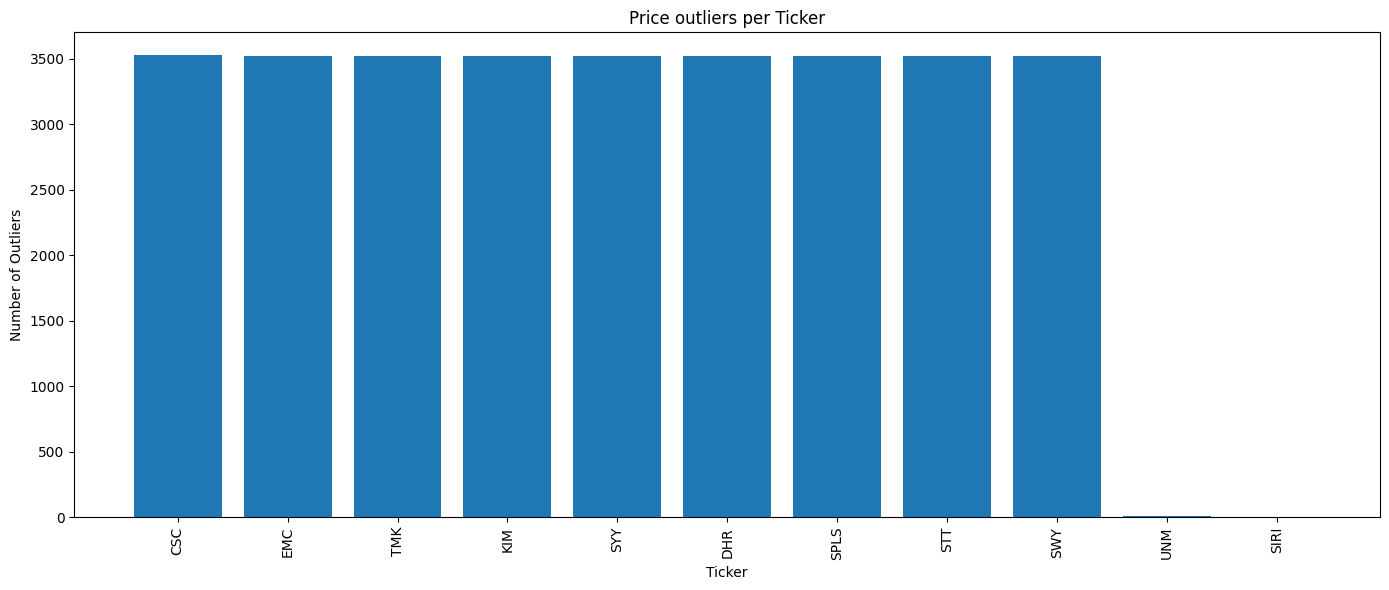

Price outliers: 31704
Return outliers: 2072


,Date,ticker,price,daily_return
444568,2000-12-12,CSC,0.0,NaN
444569,2000-12-13,CSC,0.0,NaN
444570,2000-12-14,CSC,0.0,NaN
444571,2000-12-15,CSC,0.0,NaN
444572,2000-12-18,CSC,0.0,NaN
444573,2000-12-19,CSC,0.0,NaN
444574,2000-12-20,CSC,0.0,NaN
444575,2000-12-21,CSC,0.0,NaN
444576,2000-12-22,CSC,0.0,NaN
444577,2000-12-26,CSC,0.0,NaN


,Date,ticker,price,daily_return
49003,2007-04-02,ADP,3.659642e+01,-0.793637
171734,2002-10-01,ARO,1.925926e+00,-0.577922
194376,2005-10-03,AXP,4.390351e+01,-0.711500
375640,2002-02-20,CLDX,1.272000e+01,-0.646667
380026,2005-01-03,CLF,4.386592e+01,-0.513769
444130,2013-04-18,CRM,4.103000e+01,-0.754825
448024,2014-04-03,CSC,1.399589e-317,inf
448025,2014-04-04,CSC,1.277711e-315,90.291831
448026,2014-04-07,CSC,6.706802e-314,51.490776
448027,2014-04-08,CSC,4.222249e-312,61.954727


In [44]:
long_prices = (
    stock_prices.melt(id_vars="Date", var_name="ticker", value_name="price")
    .sort_values(["ticker", "Date"])
    .reset_index(drop=True)
)

long_prices["daily_return"] = long_prices.groupby("ticker")["price"].pct_change(fill_method=None)

price_outliers = long_prices[
    ((long_prices["price"] < 0.1) | (long_prices["price"] > 10000))
    & (long_prices["price"].notna())
].copy()

return_outliers = long_prices[
    ((long_prices["daily_return"] > 1) | (long_prices["daily_return"] < -0.5))
    & (~long_prices["Date"].dt.year.isin([2008, 2009]))
    & (long_prices["price"].notna())
].copy()

def plot_outliers_per_ticker(outliers_df, value_col, filename):
    outliers_count = outliers_df.groupby(value_col).size().sort_values(ascending=False)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.bar(outliers_count.index, outliers_count.values)
    ax.set_title(f'{filename.split("_")[0].capitalize()} outliers per Ticker')
    ax.set_xlabel("Ticker")
    ax.set_ylabel("Number of Outliers")
    
    ax.tick_params(axis="x", rotation=90)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / filename, dpi=150)
    plt.show()

plot_outliers_per_ticker(return_outliers, "ticker", "return_outliers_per_ticker.png")
plot_outliers_per_ticker(price_outliers, "ticker", "price_outliers_per_ticker.png")
print("Price outliers:", len(price_outliers))
print("Return outliers:", len(return_outliers))

display(price_outliers.head(10))
display(return_outliers.head(10))

## Outliers count by Year

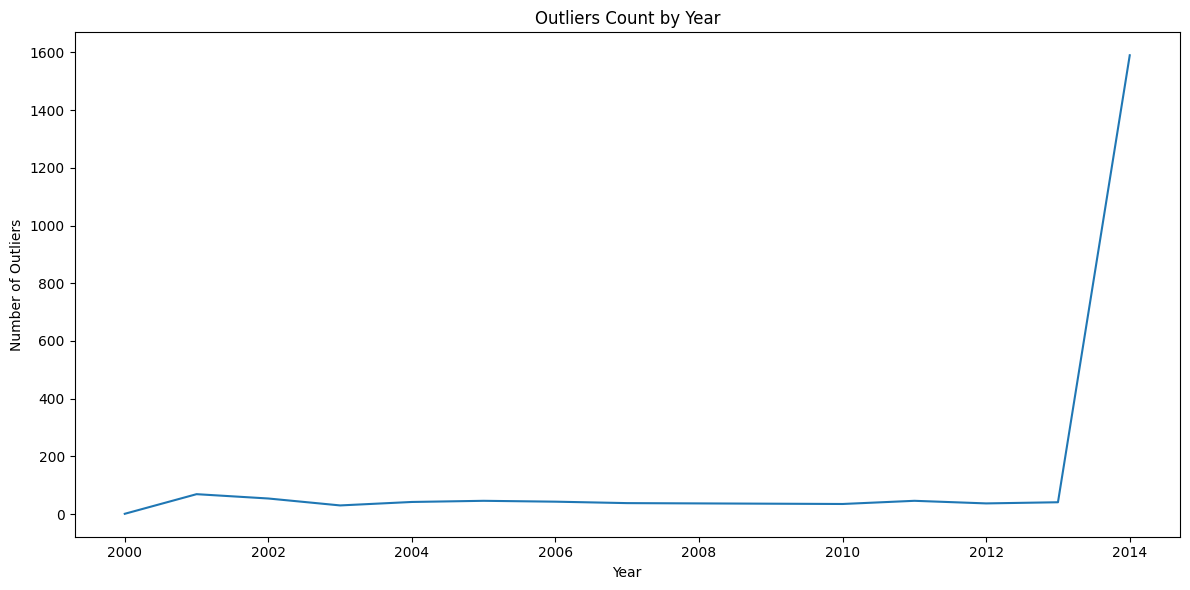

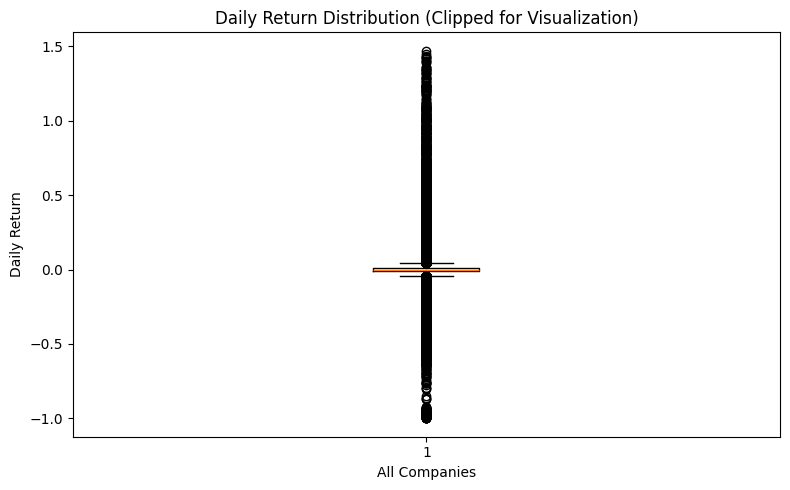

In [45]:
def save_outliers_distribution_plot(outliers_df, plot=False):
    plot_df = outliers_df.copy()
    plot_df["year"] = plot_df["Date"].dt.year
    counts = plot_df.groupby("year").size()

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(counts.index, counts.values)
    ax.set_title("Outliers Count by Year")
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of Outliers")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "outliers_count_by_year.png", dpi=150)

    if plot:
        plt.show()
    else:
        plt.close(fig)

    return counts


def save_daily_return_boxplot(long_df, plot=False):
    sample_returns = long_df["daily_return"].dropna()
    sample_returns = sample_returns[(sample_returns >= -1.5) & (sample_returns <= 1.5)]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.boxplot(sample_returns.values, vert=True)
    ax.set_title("Daily Return Distribution (Clipped for Visualization)")
    ax.set_xlabel("All Companies")
    ax.set_ylabel("Daily Return")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "daily_return_boxplot.png", dpi=150)

    if plot:
        plt.show()
    else:
        plt.close(fig)


_ = save_outliers_distribution_plot(return_outliers, plot=True)
save_daily_return_boxplot(long_prices, plot=True)

## Preparing preprocessing to find google refernces for outliers

In [46]:
import sys
import pandas as pd
import numpy as np
sys.path.insert(0, "../scripts")

# from preprocessing import preprocessing
from memory_reducer import memory_reducer

# Load data using memory_reducer (reads CSVs and reduces memory)
prices_processed, sp500_processed = memory_reducer(["../data/stock_prices.csv", "../data/sp500.csv"])

# Run preprocessing
# prices_processed, sp500_processed = preprocessing(stock, sp500_loaded)

# Build outliers summary
raw_long = (
    stock.melt(id_vars="Date", var_name="ticker", value_name="price")
    .sort_values(["ticker", "Date"])
    .reset_index(drop=True)
)
raw_long["daily_return"] = raw_long.groupby("ticker")["price"].pct_change(fill_method=None)

price_outs = raw_long[
    ((raw_long["price"] < 0.1) | (raw_long["price"] > 10000))
    & raw_long["price"].notna()
][["ticker", "Date", "price"]]

return_outs = raw_long[
    ((raw_long["daily_return"] > 1) | (raw_long["daily_return"] < -0.5))
    & (~raw_long["Date"].dt.year.isin([2008, 2009]))
    & raw_long["price"].notna()
][["ticker", "Date", "price"]]

all_outliers = (
    pd.concat([price_outs, return_outs], axis=0)
    .drop_duplicates(subset=["ticker", "Date", "price"])
    .sort_values(["ticker", "Date"])
)

# Top 5 tickers by outlier price with their min/max
top5_data = (
    all_outliers.groupby("ticker")
    .agg(
        Date=("Date", "last"),
        Min_Outlier_Price=("price", "min"),
        Max_Outlier_Price=("price", "max"),
    )
    .reset_index()
    .sort_values("Max_Outlier_Price", ascending=False)
    .head(5)
    .rename(columns={
        "ticker": "Ticker",
        "Min_Outlier_Price": "Min Outlier Price",
        "Max_Outlier_Price": "Max Outlier Price",
    })
)

print(f"{'Ticker':<10} {'Date':<14} {'Min Outlier Price':>20} {'Max Outlier Price':>20}")
print("-" * 66)
for _, row in top5_data.iterrows():
    print(f"{row['Ticker']:<10} {str(row['Date'].date())} {row['Min Outlier Price']:>20.4f} {row['Max Outlier Price']:>20.4f}")

df['Volume'] column can be presented as integer. because of .0 values
Memory usage: 15.329 MB -> 7.576 MB (stock_prices), 0.414 MB -> 0.115 MB (sp500)
Memory reduction completed
Ticker     Date              Min Outlier Price    Max Outlier Price
------------------------------------------------------------------
SPLS       2014-12-23              17.8300        93870600.0000
EMC        2014-12-26               0.0000         5961363.0000
DHR        2014-12-23               0.0000         2365042.5000
KIM        2014-12-26               0.0000         1768268.7500
SWY        2014-12-23               0.0000         1565739.3750


## Referencing historical stock prices from an external source such as Google.

| Ticker | Date | Min Outlier Price | Max Outlier Price | Verified Price | Source | Info |
|--------|------|-------------------|-------------------|----------------|--------|------|
| SPLS | 2014-12-23 | 17.81 | 93,870,600 | $11.66 | Google | Volume/Close price got messed dataset |
| EMC | 2014-12-26 | 0.0000 | 5,961,363 | $29.98 | Google | Same Volume/Close price messed dataset |
| DHR | 2014-12-23 | 0.0000 | 2,365,042 | $85.80 | Google | This time, other Volume dataset got messed with this data |
| KIM | 2014-12-26 | 0.0000 | 1,768,268 | $25.66 | Google | Volume price messed into dataset |
| SWY | 2014-12-23 | 0.0000 | 1,565,739 | $34.90 | Google | Volume price messed into dataset |

## $0.10–$10,000 outlier mask resolved this data anomaly/quality/mixed data.

## Next is Strategy-2 with Quantative EDA and analysis of outliers.
### Perform drawdown analysis, equity curve, and risk metrics to evaluate strategy performance.

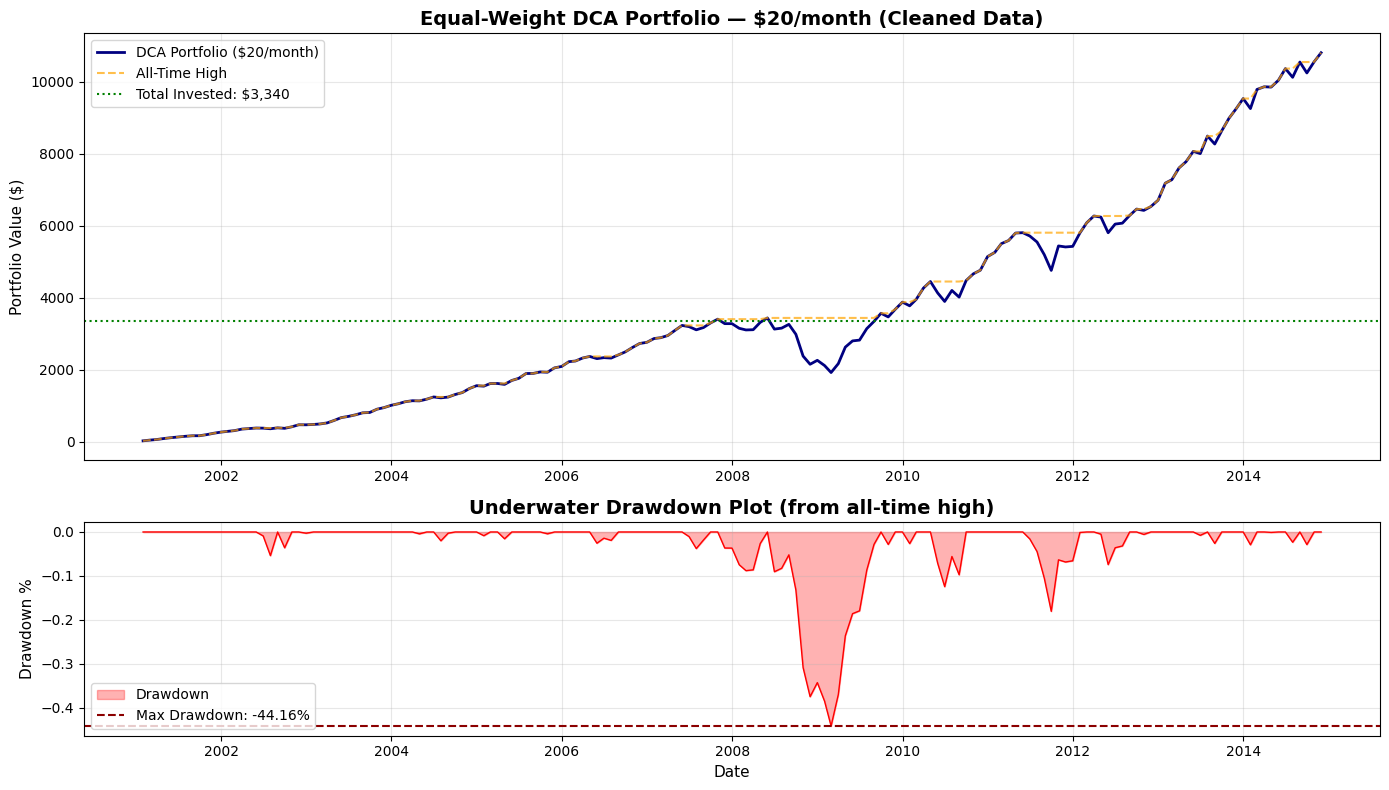

QUANTITATIVE PERFORMANCE METRICS (Equal-Weight DCA $20/month)
Months observed:        167
Total Invested:         $3,340
Final Portfolio Value:  $10,807.15
Total Return on Invested: 223.57%
Annualized Return:      8.80%
Annualized Volatility:  17.64%
Maximum Drawdown:       -44.16%
==RATIO METRICS:==
Sharpe Ratio:           0.766
Sortino Ratio:          0.299
Calmar Ratio:           0.199
==DATA QUALITY SUMMARY:==
Tickers (cleaned):      534
Price outliers removed: 31704
Return outliers removed:741


In [57]:
# Strategy Performance Analysis (quantitative, using only data from cell 10)
# ONLY WITH CELL 10 INITIALISED

import matplotlib.pyplot as plt
prices = prices_processed.copy()
prices = prices.set_index("Date").resample("ME").last()
prices = prices.apply(pd.to_numeric, errors="coerce")
prices = prices.mask((prices < 0.1) | (prices > 10000))

monthly_past_return = prices.div(prices.shift(1)).sub(1)
monthly_future_return = prices.shift(-1).div(prices).sub(1)

original_future_na_mask = monthly_future_return.isna()

non_crisis_rows = ~monthly_past_return.index.year.isin([2008, 2009])
non_crisis_mask = pd.DataFrame(
    np.repeat(non_crisis_rows[:, None], monthly_past_return.shape[1], axis=1),
    index=monthly_past_return.index,
    columns=monthly_past_return.columns,
)

past_outlier_mask = (
    (monthly_past_return > 1) | (monthly_past_return < -0.5)
) & non_crisis_mask
future_outlier_mask = (
    (monthly_future_return > 1) | (monthly_future_return < -0.5)
) & non_crisis_mask

monthly_past_return = monthly_past_return.mask(past_outlier_mask)
monthly_future_return = monthly_future_return.mask(future_outlier_mask)

prices = prices.ffill()
monthly_past_return = monthly_past_return.ffill()
monthly_future_return = monthly_future_return.ffill()
monthly_future_return = monthly_future_return.mask(original_future_na_mask)

prices_long = prices.stack().rename("Price")
past_long = monthly_past_return.stack().rename("monthly_past_return")
future_long = monthly_future_return.stack().rename("monthly_future_return")

prices = pd.concat([prices_long, past_long, future_long], axis=1)
prices.index.names = ["Date", "ticker"]
prices = prices.sort_index().dropna()

sp500_quantative = sp500_processed.copy()
sp500_quantative["Date"] = pd.to_datetime(sp500_quantative["Date"])
sp500_quantative = sp500_quantative.sort_values("Date")
sp500_quantative = sp500_quantative.set_index("Date").resample("ME").last()
sp500_quantative["monthly_past_return"] = (
    sp500_quantative["Adjusted Close"].div(sp500_quantative["Adjusted Close"].shift(1)).sub(1)
)
sp500_quantative = sp500_quantative[["Adjusted Close", "monthly_past_return"]].dropna()

# Equal-weight portfolio: average monthly return across all tickers per Date
portfolio_returns = (
    prices["monthly_past_return"]
    .dropna()
    .groupby(level="Date")
    .mean()
    .sort_index()
)

# 1. DCA Equity Curve: invest $20 every month (Dollar-Cost Averaging)
# Each month: deposit $20 into existing portfolio, then apply that month's return
monthly_investment = 20
portfolio_value = 0.0
equity_values = []
for date, ret in portfolio_returns.items():
    portfolio_value = (portfolio_value + monthly_investment) * (1 + ret)
    equity_values.append(portfolio_value)

equity_curve = pd.Series(equity_values, index=portfolio_returns.index)
total_invested = monthly_investment * len(portfolio_returns)

# 2. Drawdown: standard cumulative max (from all-time high)
rolling_max = equity_curve.cummax()
drawdown = (equity_curve - rolling_max) / rolling_max
max_drawdown = drawdown.min()

# 3. Returns & Risk Metrics (monthly -> annualize with sqrt(12))
total_return = (equity_curve.iloc[-1] / total_invested) - 1
n_months = len(portfolio_returns)
annualized_return = (1 + total_return) ** (12 / n_months) - 1
annualized_vol = portfolio_returns.std() * np.sqrt(12)

risk_free_monthly = 0.02 / 12
excess = portfolio_returns - risk_free_monthly
sharpe = excess.mean() / portfolio_returns.std() * np.sqrt(12)
downside_std = portfolio_returns[portfolio_returns < 0].std() * np.sqrt(12)
sortino = excess.mean() * np.sqrt(12) / downside_std
calmar = annualized_return / abs(max_drawdown) if max_drawdown != 0 else 0

# 4. Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(equity_curve.index, equity_curve.values, color="navy", label="DCA Portfolio ($20/month)", linewidth=2)
ax1.plot(equity_curve.index, rolling_max.values, color="orange", linestyle="--", label="All-Time High", alpha=0.7)
ax1.axhline(total_invested, color="green", linestyle=":", linewidth=1.5, label=f"Total Invested: ${total_invested:,.0f}")
ax1.set_title("Equal-Weight DCA Portfolio — $20/month (Cleaned Data)", fontsize=14, fontweight="bold")
ax1.set_ylabel("Portfolio Value ($)", fontsize=11)
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

ax2.fill_between(drawdown.index, drawdown.values, 0, color="red", alpha=0.3, label="Drawdown")
ax2.plot(drawdown.index, drawdown.values, color="red", linewidth=1)
ax2.axhline(max_drawdown, color="darkred", linestyle="--", label=f"Max Drawdown: {max_drawdown:.2%}")
ax2.set_title("Underwater Drawdown Plot (from all-time high)", fontsize=14, fontweight="bold")
ax2.set_ylabel("Drawdown %", fontsize=11)
ax2.set_xlabel("Date", fontsize=11)
ax2.legend(loc="lower left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "strategy_performance_cleaned.png", dpi=150)
plt.show()

# 5. Metrics
print("QUANTITATIVE PERFORMANCE METRICS (Equal-Weight DCA $20/month)")
print(f"Months observed:        {n_months}")
print(f"Total Invested:         ${total_invested:,.0f}")
print(f"Final Portfolio Value:  ${equity_curve.iloc[-1]:,.2f}")
print(f"Total Return on Invested: {total_return:.2%}")
print(f"Annualized Return:      {annualized_return:.2%}")
print(f"Annualized Volatility:  {annualized_vol:.2%}")
print(f"Maximum Drawdown:       {max_drawdown:.2%}")
print("==RATIO METRICS:==")
print(f"Sharpe Ratio:           {sharpe:.3f}")
print(f"Sortino Ratio:          {sortino:.3f}")
print(f"Calmar Ratio:           {calmar:.3f}")
print("==DATA QUALITY SUMMARY:==")
print(f"Tickers (cleaned):      {prices.index.get_level_values('ticker').nunique()}")
print(f"Price outliers removed: {len(price_outs)}")
print(f"Return outliers removed:{len(return_outs)}")
print("=" * 60)